In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [2]:
# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

# Display dataset shapes
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [3]:
print("Number of training samples:", len(X_train))
print("Number of testing samples:", len(X_test))

print("Unique digit classes:", np.unique(y_train))

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Number of training samples: 60000
Number of testing samples: 10000
Unique digit classes: [0 1 2 3 4 5 6 7 8 9]
Minimum pixel value: 0
Maximum pixel value: 255


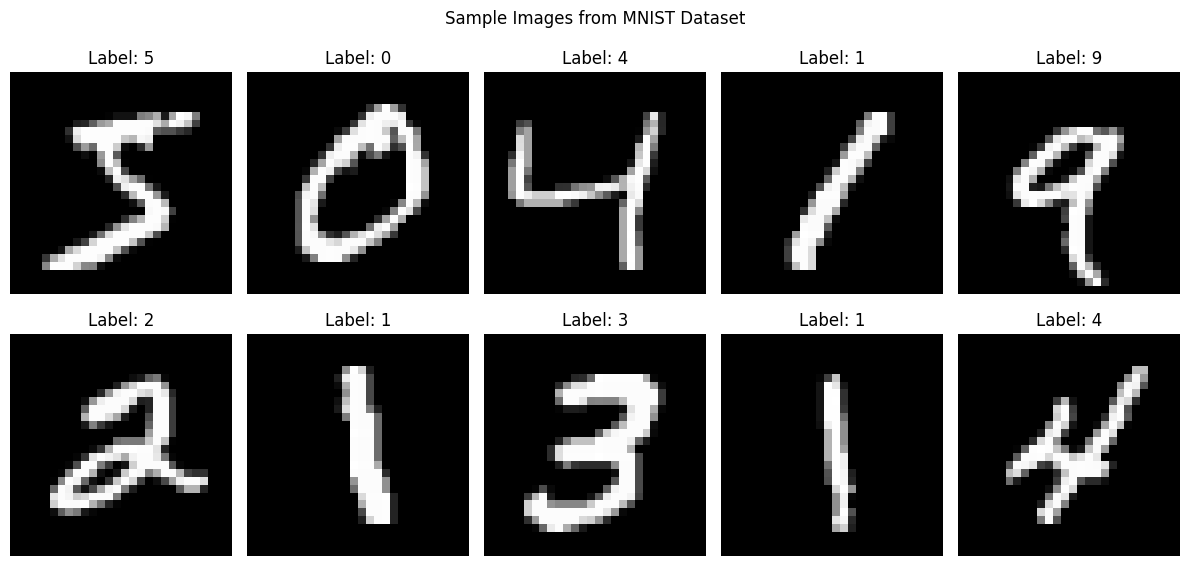

In [4]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.suptitle("Sample Images from MNIST Dataset")
plt.tight_layout()
plt.show()

In [5]:
# Normalize pixel values

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Training data range:", X_train.min(), "to", X_train.max())
print("Testing data range:", X_test.min(), "to", X_test.max())

Training data range: 0.0 to 1.0
Testing data range: 0.0 to 1.0


In [6]:
# Reshape images for CNN

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("New training shape:", X_train.shape)
print("New testing shape:", X_test.shape)

New training shape: (60000, 28, 28, 1)
New testing shape: (10000, 28, 28, 1)


In [7]:
# Build CNN model

model = keras.Sequential([

    layers.Input(shape=(28, 28, 1)),

    # First convolutional layer
    layers.Conv2D(32, (3, 3), activation='relu'),

    # First pooling layer
    layers.MaxPooling2D((2, 2)),

    # Second convolutional layer
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Second pooling layer
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a vector
    layers.Flatten(),

    # Dropout to reduce overfitting
    layers.Dropout(0.3),

    # Fully connected layer
    layers.Dense(64, activation='relu'),

    # Output layer for 10 digit classes
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [9]:
# Train the CNN model

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 50s 59ms/step - accuracy: 0.9290 - loss: 0.2308 - val_accuracy: 0.9737 - val_loss: 0.0856
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.9790 - loss: 0.0686 - val_accuracy: 0.9834 - val_loss: 0.0552
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.9837 - loss: 0.0522 - val_accuracy: 0.9865 - val_loss: 0.0456
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 56ms/step - accuracy: 0.9868 - loss: 0.0412 - val_accuracy: 0.9897 - val_loss: 0.0359
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.9895 - loss: 0.0343 - val_accuracy: 0.9888 - val_loss: 0.0391
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 84s 59ms/step - accuracy: 0.9905 - loss: 0.0298 - val_accuracy: 0.9902 - val_loss: 0.0343
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.9919 - loss: 0.0248 - val_accuracy: 0.9902 - val_loss: 0.0371
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 57ms/step - accuracy: 0.9929 - loss: 0.0217 - 

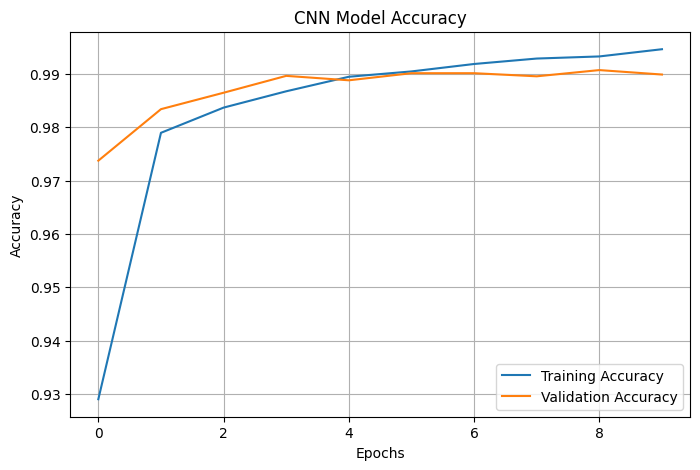

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("CNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

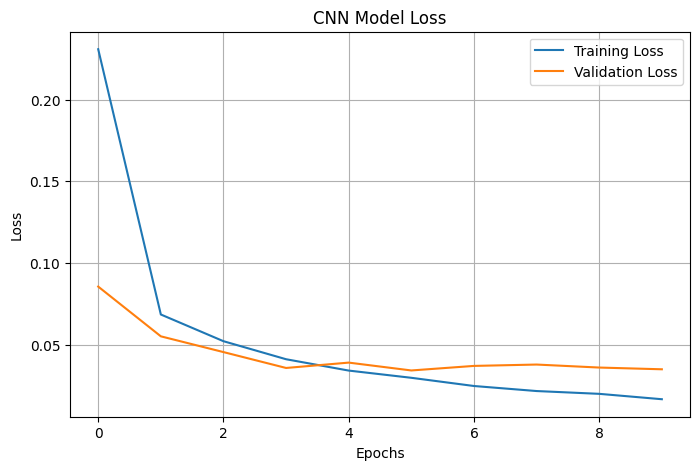

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("CNN Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [12]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9910 - loss: 0.0291
Test Loss: 0.029115887358784676
Test Accuracy: 99.09999966621399 %


In [13]:
# Predict testing images

y_pred_prob = model.predict(X_test)

# Convert probabilities into predicted classes
y_pred = np.argmax(y_pred_prob, axis=1)

print("Actual labels:", y_test[:10])
print("Predicted labels:", y_pred[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Actual labels: [7 2 1 0 4 1 4 9 5 9]
Predicted labels: [7 2 1 0 4 1 4 9 5 9]


In [14]:
print("Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        digits=4
    )
)

Classification Report:
              precision    recall  f1-score   support

           0     0.9908    0.9939    0.9924       980
           1     0.9913    0.9991    0.9952      1135
           2     0.9961    0.9826    0.9893      1032
           3     0.9911    0.9901    0.9906      1010
           4     0.9859    0.9969    0.9914       982
           5     0.9877    0.9910    0.9894       892
           6     0.9968    0.9823    0.9895       958
           7     0.9827    0.9971    0.9899      1028
           8     0.9948    0.9877    0.9912       974
           9     0.9930    0.9881    0.9906      1009

    accuracy                         0.9910     10000
   macro avg     0.9910    0.9909    0.9909     10000
weighted avg     0.9910    0.9910    0.9910     10000



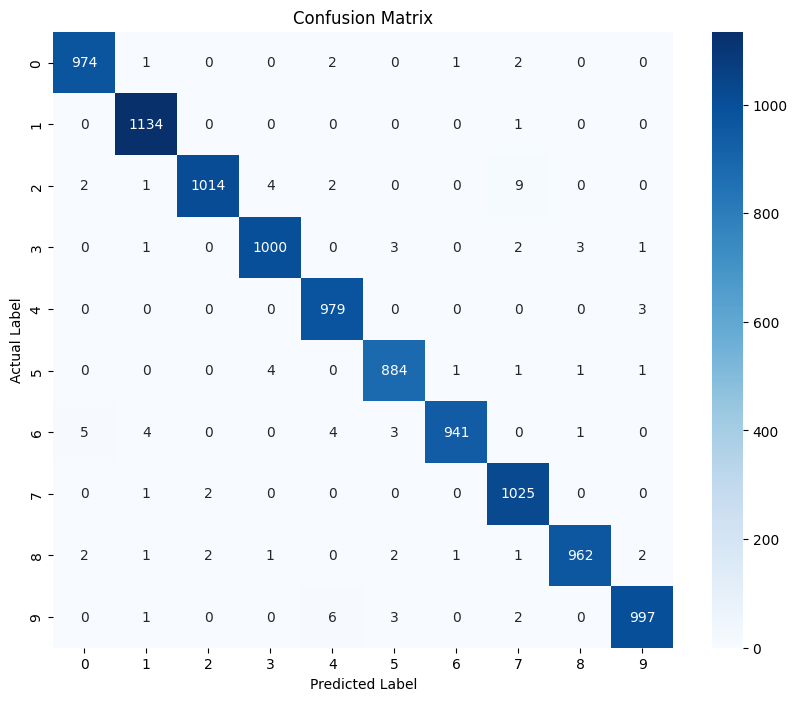

In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [16]:
accuracy = accuracy_score(y_test, y_pred)

print("Overall Model Accuracy:", accuracy * 100, "%")

Overall Model Accuracy: 99.1 %


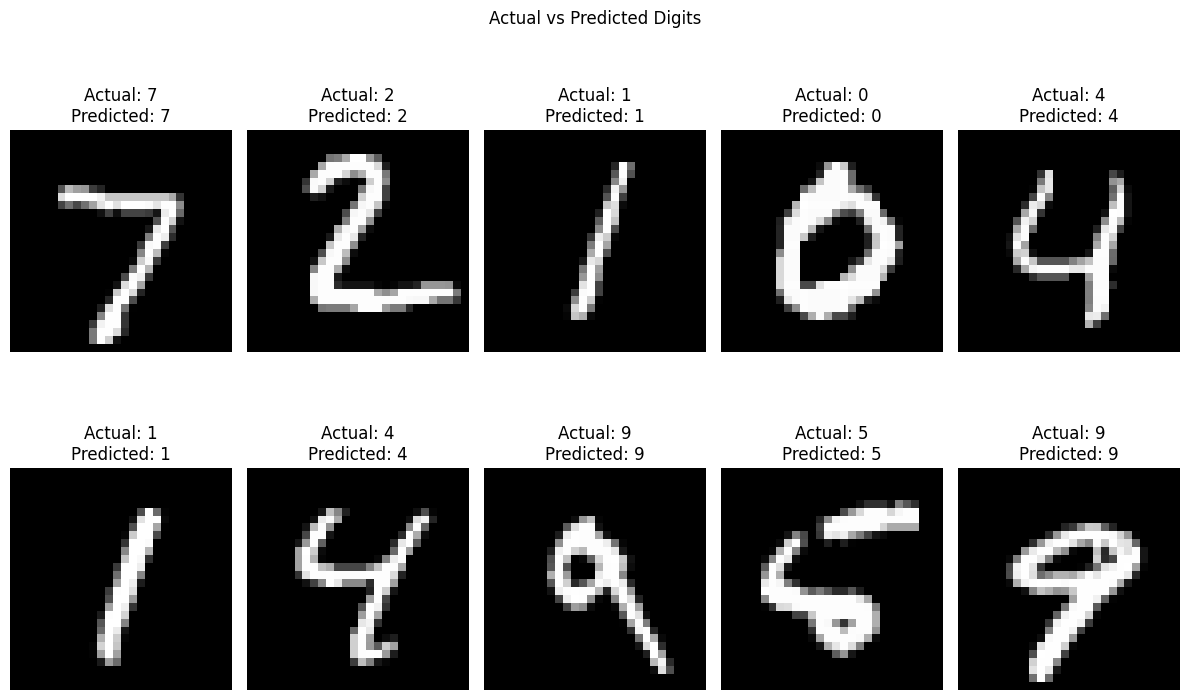

In [17]:
plt.figure(figsize=(12, 8))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}"
    )

    plt.axis('off')

plt.suptitle("Actual vs Predicted Digits")
plt.tight_layout()
plt.show()

Actual Digit: 9
Predicted Digit: 9
Prediction Confidence: 100.0 %


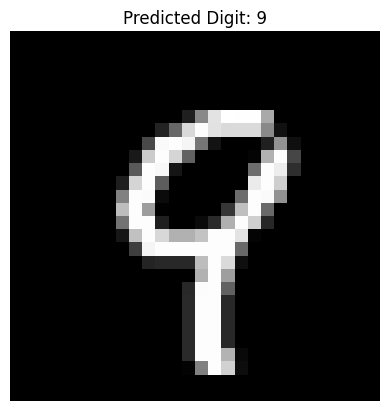

In [18]:
# Select a random test image

index = np.random.randint(0, len(X_test))

image = X_test[index]
actual_label = y_test[index]

prediction = model.predict(
    image.reshape(1, 28, 28, 1),
    verbose=0
)

predicted_label = np.argmax(prediction)

print("Actual Digit:", actual_label)
print("Predicted Digit:", predicted_label)
print(
    "Prediction Confidence:",
    round(np.max(prediction) * 100, 2),
    "%"
)

plt.imshow(image.reshape(28, 28), cmap='gray')
plt.title(f"Predicted Digit: {predicted_label}")
plt.axis('off')
plt.show()

In [19]:
print("Final Training Accuracy:",
      history.history['accuracy'][-1] * 100)

print("Final Validation Accuracy:",
      history.history['val_accuracy'][-1] * 100)

print("Final Training Loss:",
      history.history['loss'][-1])

print("Final Validation Loss:",
      history.history['val_loss'][-1])

print("Testing Accuracy:",
      test_accuracy * 100)

Final Training Accuracy: 99.46666955947876
Final Validation Accuracy: 98.99166822433472
Final Training Loss: 0.016737384721636772
Final Validation Loss: 0.03504687920212746
Testing Accuracy: 99.09999966621399


In [20]:
# Save trained model

model.save("Week5_CNN_Model.keras")

print("Model saved successfully!")

Model saved successfully!


In [21]:
from google.colab import files

files.download("Week5_CNN_Model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
# Install required packages
!pip install pydot graphviz

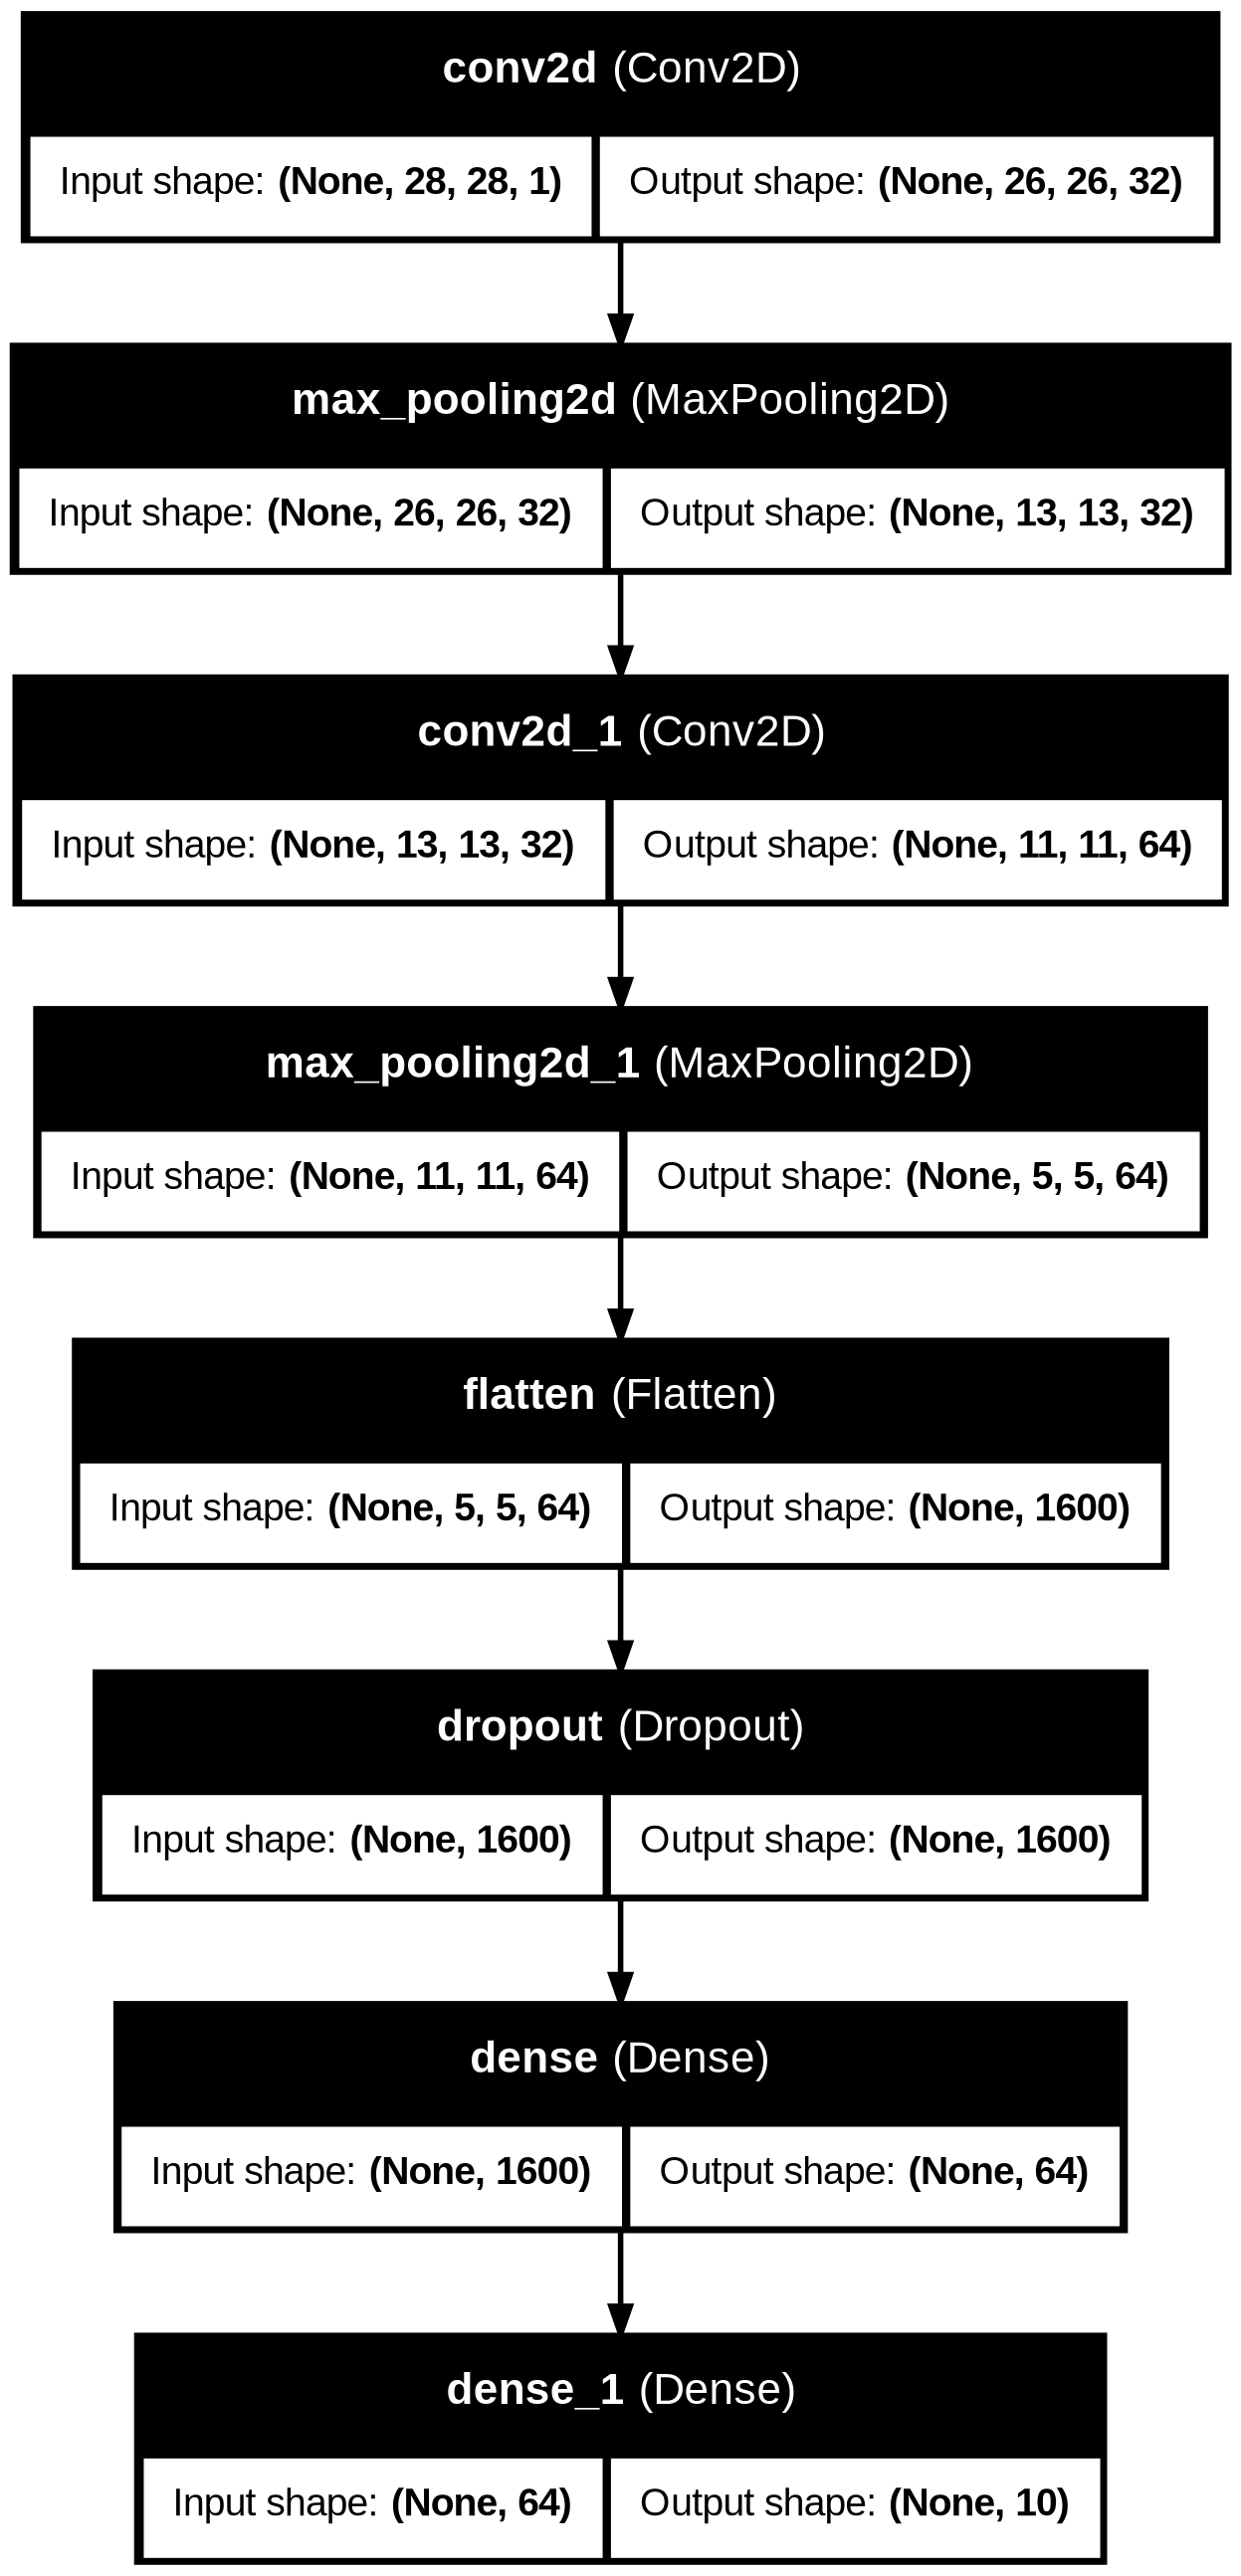

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
from tensorflow.keras.utils import plot_model

plot_model(
    model,
    to_file='CNN_Architecture.png',
    show_shapes=True,
    show_layer_names=True,
    show_dtype=False
)

from IPython.display import Image, display

display(Image('CNN_Architecture.png'))
files.download("CNN_Architecture.png")